# 신경망의 시작 - 논리 연산/논리 회로 학습
## XOR 문제
- 논리 연산
    - 기본 연산: and, or, not
    - 응용 연산: xor, nand
    - 진리표 
    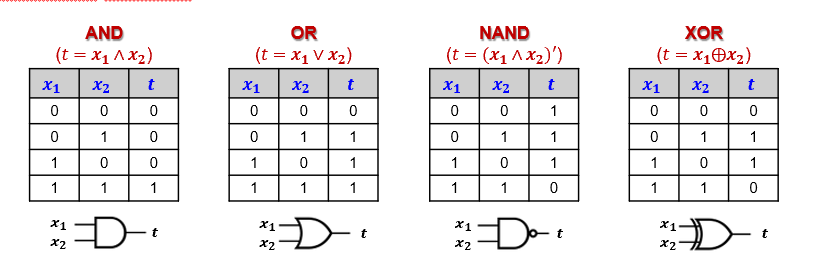
    - 논리 연산의 논리 테이블은 입력 데이터 x1, x2와 출력 t로 주어지는 학습 데이터에 의한 2-변수 logistic regression과 동일
        - 즉, 논리의 학습은 cross-entropy를 손실함수로 이용해서 logistic regression 알고리즘으로 데이터를 분류하여 결과 예측 가능
- 논리 연산 학습기와 뉴런 구조
    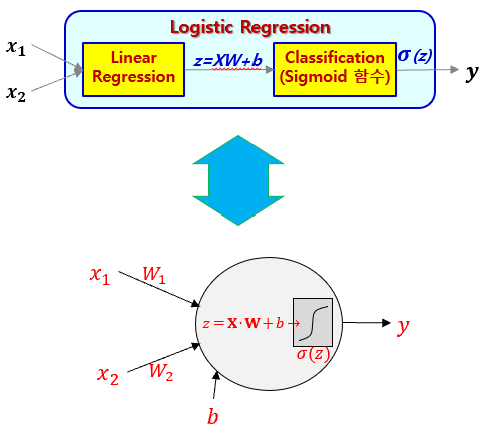
- 논리 연산 학습
    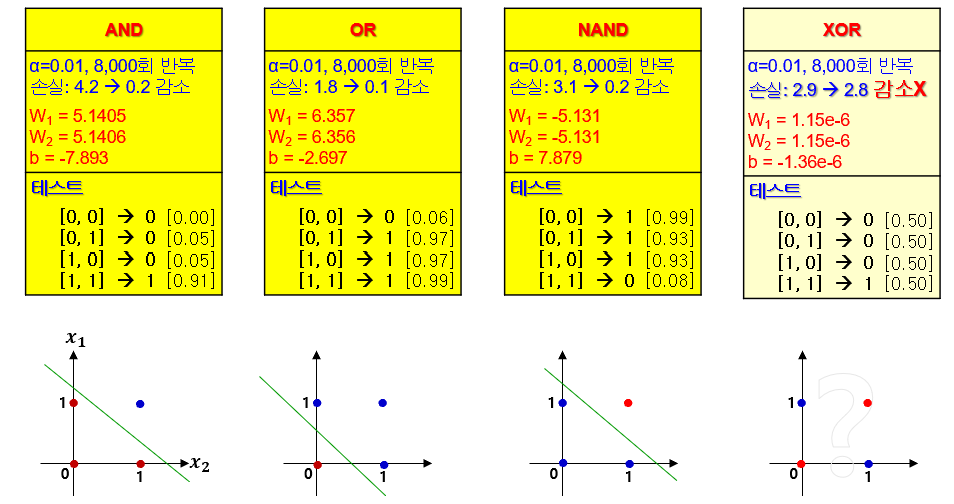
- XOR 구현
    - 단일 뉴런으로는 불가능
    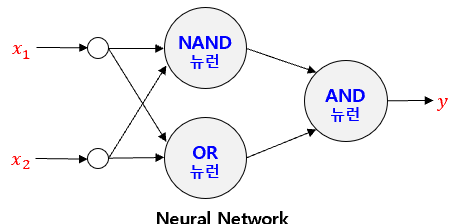
    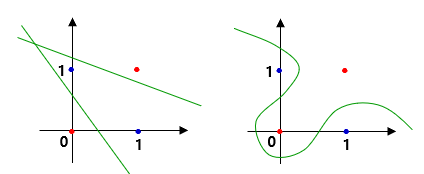
    - 뉴런 여러 개로 Multi-Layer의 망 구조로 구현 가능
        - 각각의 뉴런(nand, or, and 게이트)들은 logistic 회귀로 잘 동작
        - 입력은 화살표 방향으로 들어가며, 이전 레이어 뉴런들의 출력이 다음 레이어 뉴런의 입력으로 -> 신경망 구조를 형성 -> Neural Network
        - Multi layer NN 구성: 학습은 어떻게?
        - Backpropagation
    - 최근 딥러닝의 핵심 기술
    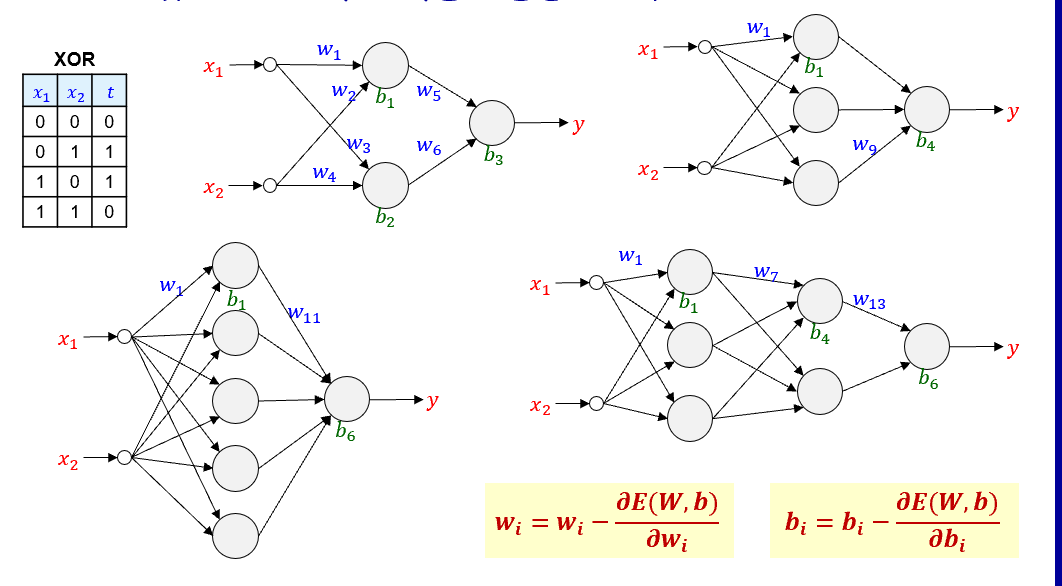
## 다층 신경망
- 입력층과 출력층 사이에 1개 이상의 Hidden layer를 가지는 신경망
    - 은닉층이 많아지면 학습의 정확도가 높아짐 -> 학습 과정이 어려워짐
    - 보통 2, 3개 이상의 은닉층을 가지면 Deep Neural Network라 함 -> Deep learning
### Error Backpropagetion
- 수치미분 보정 vs 오차 역전파 보정
    - 수치 미분
        - 수치 미분 방식은 많은 계산 시간을 요구
            - 가중치 개수만큼 입력을 신경망에 흘려보내야 함
        - 출력단의 오차만을 이용해 신경망의 모든 가중치를 출력오차 미분으로 수정함(각 노드의 기능, 역할과는 무관하게)
    - 오차 역전파
        - 출력단의 오차를 이용해 신경망을 역방향으로 전파하면서 순차적으로 오차 미분하면서 순차적으로 가중치들을 수정
        - 수학적 미분을 적용하여 공식화가 가능
        - 특히 가중치는 행렬로 표현됨으로 공식화된 행렬 알고리즘 적용 가능 (미분 계산이 없으면 빠르게 수행 가능)
        - TensorFlow는 행렬 계산이 매우 빠르므로 매우 큰 신경망도 빠르게 학습 가능함
### 신경망 예제
- 필기체 숫자 인식 (MNIST 데이터셋)
    - Modified National Institute of Standards and Technology
    - 신경망 분야의 유명한 데이터셋 - 기초부터 연구까지 다양하게 활용
    - 6만개의 학습 데이터와 1만개의 테스트 데이터
    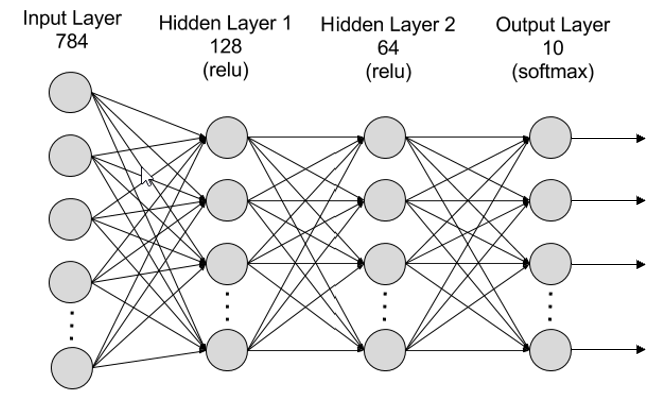
## 딥러닝
- 고려사항
    - Geoffrey Hinton's summary of findings up to today
        1. labeled datasets가 적다
        2. computer가 느리다
        3. 가중치를 멍청하게 시작함
        4. 잘못된 비선형 데이터 사용
    - 과적합 -> more dataset, drop out, regularization
    - 컴퓨터도 훨씬 빨라야 함 -> GPU, TPU 발전
    - 초기 가중치를 임의로 주면 어려움 -> RBM, Xavier/He
    - 은닉층 층수와 노드수를 신중하게 계획해야 함
    - 시그모이드 함수는 딥러닝에 맞지 않음
        - 은닉층이 많아질 시 시그모이드 함수는 Gradient vanishing
        - 대안: ReLU, Tanh, leaky ReLU, ELU ReLU, Maxout ReLU



# 행렬, 선형변환
- 입력이 가중치 행렬을 통과하는 것과 가중치 행렬이 입력을 변환하는 것은 같은 결과를 도출할 수 있음

- $X \cdot W = (W^T \cdot X^T)^T$

$$
\underbrace{
\begin{pmatrix}
  0 & 0 \\
  0 & 1 \\
  1 & 0 \\
  1 & 1
\end{pmatrix}
}_{X\;(4\times2)}
\cdot
\underbrace{
\begin{pmatrix}
  w_{11} & w_{12} & w_{13} & w_{14} & w_{15} \\
  w_{21} & w_{22} & w_{23} & w_{24} & w_{25}
\end{pmatrix}
}_{W\;(2\times5)}
=
\left(
\underbrace{
\begin{pmatrix}
  w_{11} & w_{21} \\
  w_{12} & w_{22} \\
  w_{13} & w_{23} \\
  w_{14} & w_{24} \\
  w_{15} & w_{25}
\end{pmatrix}
}_{W^T\;(5\times2)}
\cdot
\underbrace{
\begin{pmatrix}
  0 & 0 & 1 & 1 \\
  0 & 1 & 0 & 1
\end{pmatrix}
}_{X^T\;(2\times4)}
\right)^T
$$

In [1]:
import numpy as np

M = np.array([[0, 1],
              [1, 0]])
org = np.array([1, 2])

res = M @ org.T
print(res)

res = org @ M.T
print(res)

[2 1]
[2 1]


In [2]:
# 은닉층 함수 구현
from datetime import datetime

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def cross_entropy(t, y):
    delta = 1e-7
    return -np.sum(t*np.log(y+delta) + (1-t)*np.log((1-y)+delta))

def numerical_derivative(f, x):
    delta_x = 1e-4
    grad = np.zeros_like(x)
    
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    
    while not it.finished:
        idx = it.multi_index
        tmp_val = x[idx]
        x[idx] = float(tmp_val) + delta_x
        fx1 = f(x) #(x+delta_x)
        
        x[idx] = tmp_val - delta_x
        fx2 = f(x) #(x-delta_x)
        grad[idx] = (fx1 - fx2) / (2*delta_x)
        
        x[idx] = tmp_val
        it.iternext()
    return grad

class LogicGate:
    def __init__(self, gate_name, xdata, tdata, hidden = 5):
        self.name = gate_name
        # 입력 데이터, 정답 데이터 초기화
        rows, cols = len(xdata), len(xdata[0])
        self.xdata = xdata.reshape(rows, cols) # 4개의 입력 데이터 x1, x2에 대해 batch 처리 행렬
        self.tdata = tdata.reshape(rows, 1) # 4개의 입력데이터 x1, x2에 대한 계산 값 행렬
        
        # 2층 hidden layer: 5개 가정, 가중치 W2, 편향 b2 초기화
        self.W2 = np.random.rand(cols, hidden) # 2x5
        self.b2 = np.random.rand(hidden)
        
        # 3층 output layer unit: 1개, 가중치 W3, 편향 b3 초기화
        self.W3 = np.random.rand(hidden, 1) # 5x1
        self.b3 = np.random.rand(1)
        
        # 학습률 초기화
        self.lr = 1e-2
        print(self.name + "object is created")
        
    def feed_forward(self):
        z2 = self.xdata @ self.W2 + self.b2 # 은닉층의 선형회귀
        a2 = sigmoid(z2) # 은닉층의 활성화 함수 적용
        z3 = a2 @ self.W3 + self.b3 # 출력층의 선형회귀
        y = a3 = sigmoid(z3) # 출력층의 활성화 함수 적용
        return cross_entropy(self.tdata, y) # 손실값 리턴
    
    def errValue(self): # 외부 출력을 위한 손실함수 값 계산
        return self.feed_forward()
    
    def train(self, repeat = 8000, outStep = 1000):
        f = lambda x: self.feed_forward()
        start = datetime.now()
        for step in range(repeat + 1):
            self.W2 -= self.lr * numerical_derivative(f, self.W2)
            self.b2 -= self.lr * numerical_derivative(f, self.b2)
            self.W3 -= self.lr * numerical_derivative(f, self.W3)
            self.b3 -= self.lr * numerical_derivative(f, self.b3)
            
            if step % outStep == 0:
                print("step = ", step, "error value = ", self.errValue())
        end = datetime.now()
        print("elapsed time = ", end - start)
        
    def predict(self, test):
        z2 = test @ self.W2 + self.b2 # 은닉층의 선형회귀
        a2 = sigmoid(z2) # 은닉층의 활성화 함수 적용
        z3 = a2 @ self.W3 + self.b3 # 출력층의 선형회귀
        y = a3 = sigmoid(z3) # 출력층의 활성화 함수 적용
        if y > 0.5:
            result = 1
        else:
            result = 0
        return y, result


In [3]:
# XOR gate 학습
xdata = np.array([[0, 0],
                  [0, 1],
                  [1, 0],
                  [1, 1]])
tdata = np.array([[0],
                  [1],
                  [1],
                  [0]])

XOR = LogicGate("XOR", xdata, tdata)
XOR.train(repeat = 15000)

XORobject is created
step =  0 error value =  4.628464947926172
step =  1000 error value =  2.7668194997424385
step =  2000 error value =  2.7592259701312036
step =  3000 error value =  2.742602327162402
step =  4000 error value =  2.7037550126394025
step =  5000 error value =  2.6184575593242676
step =  6000 error value =  2.4523196760056605
step =  7000 error value =  2.164488709210632
step =  8000 error value =  1.7194203422148737
step =  9000 error value =  1.191929215167706
step =  10000 error value =  0.7847470194493614
step =  11000 error value =  0.5397082522424205
step =  12000 error value =  0.3960282035999218
step =  13000 error value =  0.3069976154785319
step =  14000 error value =  0.24814790481843146
step =  15000 error value =  0.20700709005887022
elapsed time =  0:00:18.331891


In [6]:
print("===", XOR.name, "testing...")
test_data = np.array([[0, 0],
                      [0, 1],
                      [1, 0],
                      [1, 1],
                      [0.7, 0.3]])
for test in test_data:
    y = XOR.predict(test)
    print(test, " = ", y[1], " (softmax = ", y[0], ")")

=== XOR testing...
[0. 0.]  =  0  (softmax =  [0.01074896] )
[0. 1.]  =  1  (softmax =  [0.94858975] )
[1. 0.]  =  1  (softmax =  [0.94515308] )
[1. 1.]  =  0  (softmax =  [0.08333493] )
[0.7 0.3]  =  1  (softmax =  [0.5192493] )


In [7]:
# XOR 3-in gate
xdata = np.array([[0, 0, 0],
                  [0, 0, 1],
                  [0, 1, 0],
                  [0, 1, 1],
                  [1, 0, 0],
                  [1, 0, 1],
                  [1, 1, 0],
                  [1, 1, 1]])
tdata = np.array([[0],
                  [1],
                  [1],
                  [0],
                  [1],
                  [0],
                  [0],
                  [1]])

XOR3 = LogicGate("XOR3", xdata, tdata, hidden = 16)
XOR3.train(repeat = 15000)

XOR3object is created
step =  0 error value =  20.934933271746637
step =  1000 error value =  5.544553191467131
step =  2000 error value =  5.542876069505688
step =  3000 error value =  5.5411483231553
step =  4000 error value =  5.539057640087332
step =  5000 error value =  5.536174854303001
step =  6000 error value =  5.531744743535665
step =  7000 error value =  5.524263077082503
step =  8000 error value =  5.51053164791025
step =  9000 error value =  5.483334055517815
step =  10000 error value =  5.425004007700724
step =  11000 error value =  5.2943603642874795
step =  12000 error value =  5.04188737964179
step =  13000 error value =  4.692619824186531
step =  14000 error value =  4.315072161520325
step =  15000 error value =  3.9332156209752345
elapsed time =  0:00:51.251585


In [8]:
test_data = np.array([[0, 0, 0],
                      [0, 0, 1],
                      [0, 1, 0],
                      [0, 1, 1],
                      [1, 0, 0],
                      [1, 0, 1],
                      [1, 1, 0],
                      [1, 1, 1],
                      [0.7, 0.3, 0.5]])

for test in test_data:
    y = XOR3.predict(test)
    print(test, " = ", y[1], " (softmax = ", y[0], ")")

[0. 0. 0.]  =  0  (softmax =  [0.16514455] )
[0. 0. 1.]  =  1  (softmax =  [0.75945513] )
[0. 1. 0.]  =  1  (softmax =  [0.76350291] )
[0. 1. 1.]  =  0  (softmax =  [0.42877395] )
[1. 0. 0.]  =  1  (softmax =  [0.7602607] )
[1. 0. 1.]  =  0  (softmax =  [0.42558335] )
[1. 1. 0.]  =  0  (softmax =  [0.42661931] )
[1. 1. 1.]  =  0  (softmax =  [0.2827879] )
[0.7 0.3 0.5]  =  1  (softmax =  [0.58998308] )


# Scikit-learn
## 개요
- Numpy와 Scipy 위에서 구축된 라이브러리
    - 구글 summer project, SciKit(Scipy toolkit)에서 시작
    - 오랜 기간 사용되어 성숙한 라이브러리
    - 파이썬 설치 시 기본적으로 설치됨
- 데이터 마이닝과 머신러닝을 위한 하이레벨 라이브러리
    - 지도학습, 비지도학습에 관련된 다양한 메서드를 제공하기 때문에 간단하게 학습 알고리즘을 사용하려 할 때 효율적
    - 주로 Decision tree, Regression, svm, k-NN, ensenble, PCA와 같은 머신러닝 메서드 제공
    - 딥러닝이나 강화학습은 다루지 않음
    - 텐서플로우는 상대적으로 로우레벨 라이브러리에 가까움
        - 텐서플로우는 신경망이나 딥러닝 위주의 데이터 계산, 연산을 위한 라이브러리
        - 2020년 Keras 통합으로 하이레벨 플랫폼으로 변화
## 특징
- 다양한 머신러닝용 라이브러리 제공
- 심플하고 일관성 있는 api, 유용한 온라인 문서, 풍부한 예제
- 머신러닝을 위한 쉽고 효율적인 개발 라이브러리 제공
- 많은 사람들이 사용하며 다양한 환경에서 검증된 라이브러리
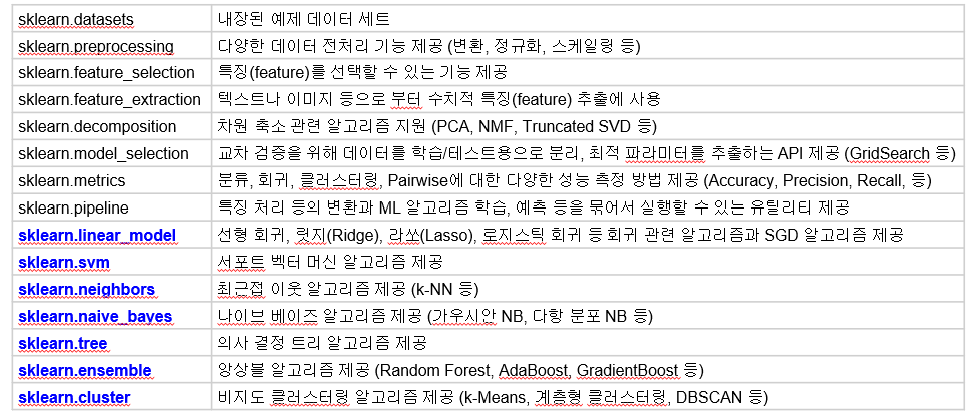

## Estimator API 사용
- 적절한 estimator 클래스를 임포트해서 모델의 클래스 선택
- 클래스를 원하는 값으로 인스턴스화해서 모델의 하이퍼 파라미터 선택
- 데이터를 특징 배열과 타겟 벡터로 배치
- 모델 인스턴스의 fit() 메서드로 데이터 학습
- 모델을 새 데이터에 대해 적용
    - 지도학습: 대체로 predict() 메서드로 예측
    - 비지도학습: transform이나 predict 메서드로 데이터의 속성을 변환하거나 추론
    

In [1]:
# 선형회귀 Scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn import set_config
from sklearn.linear_model import LinearRegression

# Avoid HTML rendering that reads bundled JavaScript with the Windows encoding.
set_config(display="text")

lrModel = LinearRegression(fit_intercept=True)
print(lrModel)

LinearRegression()


In [14]:
x = np.array([9, 14, 21, 27, 32, 37])
x = x.reshape(-1, 1) # 2차원 배열로 변환
y = np.array([74, 81, 86, 90, 88, 92])
lrModel.fit(x, y) # 선형회귀 모델 학습

LinearRegression()

In [ ]:
tx = np.array([24, 34, 11, 42])
tx = tx.reshape(-1, 1) # 2차원 배열로 변환
predicted = lrModel.predict(tx)
print("predicted = ", predicted)

predicted =  [85.55348837 91.35581395 78.01046512 95.99767442]


In [17]:
print(lrModel.coef_) # 기울기
print(lrModel.intercept_) # 절편

[0.58023256]
71.62790697674419


테스트 데이터 [ 5 10 15 20 25 30 35 40]
예측 데이터 [74.52906977 77.43023256 80.33139535 83.23255814 86.13372093 89.03488372
 91.93604651 94.8372093 ]


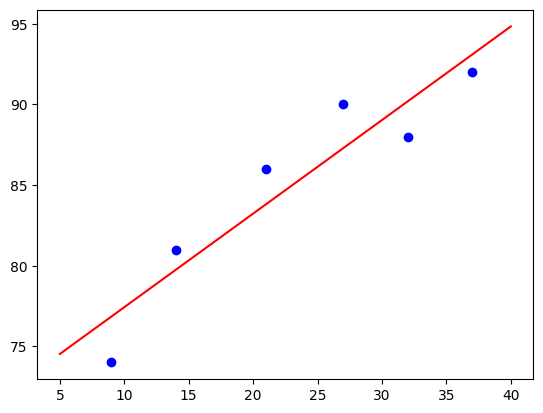

In [18]:
nx = np.arange(5, 45, 5)
nX = nx.reshape(-1, 1) # 2차원 배열로 변환
ny = lrModel.predict(nX)

print("테스트 데이터", nx)
print("예측 데이터", ny)

plt.scatter(x, y, color='blue', label='data')
plt.plot(nX, ny, color='red', label='prediction')


In [2]:
# logistic regression

import numpy as np
from sklearn.linear_model import LogisticRegression

logiMd = LogisticRegression()

x_data = np.array([ [2, 4],
                   [4, 11],
                   [6, 6],
                   [8, 5],
                   [10, 7],
                   [12, 16],
                   [14, 8],
                   [16, 3],
                   [18, 7]])

t_data = np.array([0,0,0,0,1,1,1,1,1])

logiMd.fit(x_data, t_data)
print(logiMd)

LogisticRegression()


In [3]:
print(logiMd.get_params())

{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': 0.0, 'max_iter': 100, 'n_jobs': None, 'penalty': 'deprecated', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


In [4]:
print("학습 데이터 점수: {}".format(logiMd.score(x_data, t_data)))

학습 데이터 점수: 1.0


In [5]:
test_data = np.array([[3, 17],
                      [5, 8],
                      [7, 5],
                      [9, 6],
                      [11, 9],
                      [13, 15],
                      [15, 4],
                      [17, 8],
                      [19, 2]])
logiMd.predict(test_data)


array([0, 0, 0, 0, 1, 1, 1, 1, 1])

In [6]:
print(logiMd.coef_) # 기울기
print(logiMd.intercept_) # 절편

[[0.9046569  0.30593173]]
[-10.1870571]
